# Pendulum-v1 using Q-Learning

**Name:** Replace with your name  
**Student ID:** Replace with your student ID

This experiment applies a Temporal Difference method (Q-Learning) to `Pendulum-v1`. The continuous state and action spaces are discretised so they can be represented by a Q-table. The agent is trained for 10,000 episodes.


## Method

The observation is $[\cos(\theta), \sin(\theta), \dot{\theta}]$ and the action is a torque between -2 and 2. The Q-Learning update is:

$$Q(s,a) \leftarrow Q(s,a) + \alpha[r + \gamma\max_{a'}Q(s',a') - Q(s,a)]$$

The agent uses epsilon-greedy exploration during training. A higher episode return is better because Pendulum rewards are negative costs.


## 1. Imports and parameters

In [ ]:
# Uncomment if the packages are not installed.
# %pip install "gymnasium[classic-control]" numpy matplotlib moviepy imageio-ffmpeg

from pathlib import Path
import os

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
from gymnasium.wrappers import RecordVideo

SEED = 2026
TRAINING_EPISODES = 50000
EVALUATION_EPISODES = 200

ANGLE_BINS = 36
VELOCITY_BINS = 36
ACTION_BINS = 15

GAMMA = 0.99
ALPHA = 0.18
MIN_ALPHA = 0.03
ALPHA_DECAY = 0.999

EPSILON = 1.0
MIN_EPSILON = 0.03
EPSILON_DECAY = 0.9975

np.random.seed(SEED)

OUTPUT_DIR = Path("pendulum_student_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)


## 2. Discretise the state and action spaces

The angle and angular velocity are each divided into 36 bins. The continuous torque is replaced by 15 evenly spaced actions.


In [2]:
angle_edges = np.linspace(-np.pi, np.pi, ANGLE_BINS + 1)[1:-1]
velocity_edges = np.linspace(-8.0, 8.0, VELOCITY_BINS + 1)[1:-1]
action_values = np.linspace(-2.0, 2.0, ACTION_BINS, dtype=np.float32)


def discretise_state(observation):
    cos_theta, sin_theta, angular_velocity = observation
    angle = np.arctan2(sin_theta, cos_theta)
    angle_index = np.digitize(angle, angle_edges)
    velocity_index = np.digitize(
        np.clip(angular_velocity, -8.0, 8.0),
        velocity_edges,
    )
    return int(angle_index), int(velocity_index)


q_table = np.zeros((ANGLE_BINS, VELOCITY_BINS, ACTION_BINS), dtype=np.float32)
print("Q-table shape:", q_table.shape)


Q-table shape: (36, 36, 15)


## 3. Train the Q-Learning agent

In [3]:
env = gym.make("Pendulum-v1")
rng = np.random.default_rng(SEED)

training_returns = []
epsilon = EPSILON
alpha = ALPHA

for episode in range(TRAINING_EPISODES):
    observation, info = env.reset(seed=SEED + episode)
    state = discretise_state(observation)
    terminated = False
    truncated = False
    episode_return = 0.0

    while not (terminated or truncated):
        # Epsilon-greedy action selection
        if rng.random() < epsilon:
            action_index = int(rng.integers(ACTION_BINS))
        else:
            action_index = int(np.argmax(q_table[state]))

        action = np.array([action_values[action_index]], dtype=np.float32)
        next_observation, reward, terminated, truncated, info = env.step(action)
        next_state = discretise_state(next_observation)

        # Q-Learning TD update
        future_q = 0.0 if terminated else np.max(q_table[next_state])
        td_target = reward + GAMMA * future_q
        td_error = td_target - q_table[state + (action_index,)]
        q_table[state + (action_index,)] += alpha * td_error

        state = next_state
        episode_return += reward

    training_returns.append(episode_return)
    epsilon = max(MIN_EPSILON, epsilon * EPSILON_DECAY)
    alpha = max(MIN_ALPHA, alpha * ALPHA_DECAY)

    if (episode + 1) % 500 == 0:
        recent_average = np.mean(training_returns[-100:])
        print(
            f"Episode {episode + 1}/{TRAINING_EPISODES}, "
            f"average return (last 100) = {recent_average:.2f}"
        )

env.close()
np.save(OUTPUT_DIR / "pendulum_q_table.npy", q_table)
print("Training completed.")


Episode 500/10000, average return (last 100) = -1242.63
Episode 1000/10000, average return (last 100) = -1251.71
Episode 1500/10000, average return (last 100) = -1182.81
Episode 2000/10000, average return (last 100) = -1169.83
Episode 2500/10000, average return (last 100) = -1158.02
Episode 3000/10000, average return (last 100) = -1135.86
Episode 3500/10000, average return (last 100) = -1168.27
Episode 4000/10000, average return (last 100) = -1108.22
Episode 4500/10000, average return (last 100) = -1107.64
Episode 5000/10000, average return (last 100) = -1094.55
Episode 5500/10000, average return (last 100) = -1128.84
Episode 6000/10000, average return (last 100) = -1169.10
Episode 6500/10000, average return (last 100) = -1074.67
Episode 7000/10000, average return (last 100) = -1017.10
Episode 7500/10000, average return (last 100) = -1016.16
Episode 8000/10000, average return (last 100) = -1000.91
Episode 8500/10000, average return (last 100) = -1062.01
Episode 9000/10000, average retu

## 4. Training performance

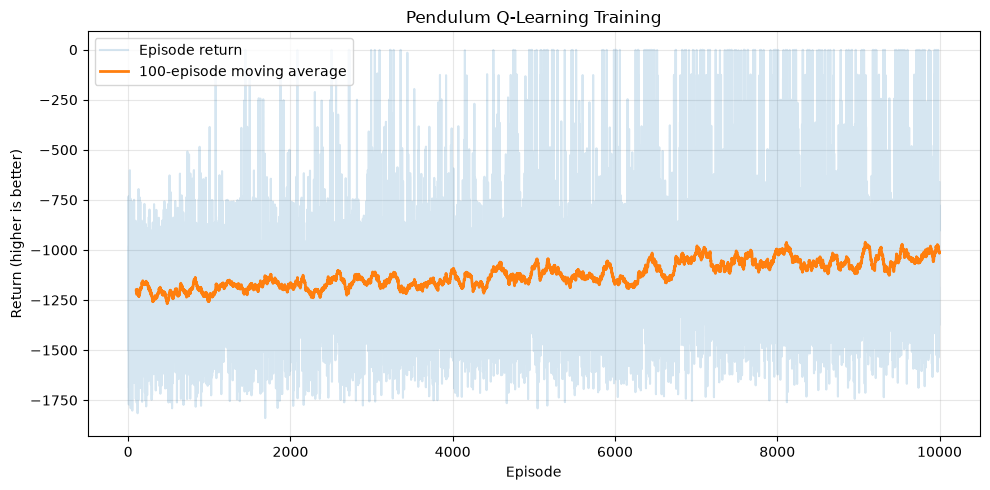

In [4]:
window = 100
moving_average = np.convolve(
    training_returns,
    np.ones(window) / window,
    mode="valid",
)

plt.figure(figsize=(10, 5))
plt.plot(training_returns, alpha=0.18, label="Episode return")
plt.plot(
    np.arange(window - 1, TRAINING_EPISODES),
    moving_average,
    linewidth=2,
    label="100-episode moving average",
)
plt.xlabel("Episode")
plt.ylabel("Return (higher is better)")
plt.title("Pendulum Q-Learning Training")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "training_curve.png", dpi=160)
plt.show()


## 5. Evaluate the trained policy

The trained greedy policy is evaluated without exploration. A random policy is included as the minimum comparison required to show that learning occurred.


In [5]:
def evaluate(use_trained_policy):
    evaluation_env = gym.make("Pendulum-v1")
    returns = []

    for episode in range(EVALUATION_EPISODES):
        observation, info = evaluation_env.reset(seed=30_000 + episode)
        evaluation_env.action_space.seed(30_000 + episode)
        terminated = False
        truncated = False
        total_reward = 0.0

        while not (terminated or truncated):
            if use_trained_policy:
                state = discretise_state(observation)
                action_index = int(np.argmax(q_table[state]))
                action = np.array([action_values[action_index]], dtype=np.float32)
            else:
                action = evaluation_env.action_space.sample()

            observation, reward, terminated, truncated, info = evaluation_env.step(action)
            total_reward += reward

        returns.append(total_reward)

    evaluation_env.close()
    return np.array(returns)


trained_returns = evaluate(use_trained_policy=True)
random_returns = evaluate(use_trained_policy=False)

print(f"Trained policy: {trained_returns.mean():.2f} ± {trained_returns.std():.2f}")
print(f"Random policy:  {random_returns.mean():.2f} ± {random_returns.std():.2f}")
print(f"Improvement:    {trained_returns.mean() - random_returns.mean():.2f}")


Trained policy: -1223.07 ± 420.89
Random policy:  -1261.86 ± 282.69
Improvement:    38.79


## 6. Record the trained agent

In [6]:
os.environ.setdefault("SDL_VIDEODRIVER", "dummy")

video_env = gym.make("Pendulum-v1", render_mode="rgb_array")
video_env = RecordVideo(
    video_env,
    video_folder=str(OUTPUT_DIR / "video"),
    episode_trigger=lambda episode_id: True,
    name_prefix="pendulum-q-learning",
    disable_logger=True,
)

observation, info = video_env.reset(seed=40_000)
terminated = False
truncated = False
video_return = 0.0

while not (terminated or truncated):
    state = discretise_state(observation)
    action_index = int(np.argmax(q_table[state]))
    action = np.array([action_values[action_index]], dtype=np.float32)
    observation, reward, terminated, truncated, info = video_env.step(action)
    video_return += reward

video_env.close()
print(f"Recorded episode return: {video_return:.2f}")
print("Video saved in:", (OUTPUT_DIR / "video").resolve())


Recorded episode return: -1071.62
Video saved in: C:\Users\James\Desktop\RL\pendulum_student_outputs\video


## 7. Short discussion

After running the notebook, report:

- the final 100-episode training average;
- the trained-policy mean and standard deviation;
- the random-policy mean and standard deviation;
- whether the trained agent performed better than random;
- whether the learning curve became stable;
- the limitation caused by discretising continuous states and torques.
